In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/.gitignore
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/AI_USAGE.md
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/README.md
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/REPLICATION_SUMMARY.md
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/compare_runs.py
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/make_tables.py
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/requirements.txt
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/run_experiments.py
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/run_phase2.py
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/run_pilot.py
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/data/cifar100_classes.txt
/kaggle/input/datasets/shreyadharwad/fvlc-phase2/fvlc-replication/data/cifar10_classes.txt
/kaggle

# EC-FVLC: making concept explanations follow the visual evidence
**DA351 Explainable AI — Phase 2 (research gap and extension).** Original paper: Lai et al., *Faithful Vision-Language Interpretation via Concept Bottleneck Models* (FVLC), ICLR 2024.

This notebook tells the Phase 2 story in charts, in the same order as the report:

| Section | Question | Figure |
|---|---|---|
| 1. Research gap | Is FVLC's stability metric enough to call an explanation faithful? | A1 |
| 2. Proposed improvement | What does the new loss L5 do? | (equation) |
| 3. Main result | Do EC-FVLC's concepts follow the visual evidence better than FVLC's? | A2 |
| 4. Before vs after | What improves, and what gets worse? | A3 |
| 5. Design choice | How strong should L5 be? | A4 |
| 6. Independent check | Do the concepts agree better with human labels? | A5 |
| 7. Inside the model | What happens to one image and its concepts under each edit? | B1–B5 |

**How to run.** Part A (sections 1–6) only reads the saved results in `results_phase2/` and takes seconds; no GPU is needed.
Part B (section 7) retrains FVLC and EC-FVLC on CIFAR-10 on a T4 GPU, with the same seed and settings as the reported runs.

**Reading the charts.** Every chart uses the same colours and marker shapes: <span style="color:#E69F00">■ orange = FVLC (before)</span>,
<span style="color:#0072B2">● blue = EC-FVLC (after, ours)</span>, ▲ grey = reference (LF-CBM, CLIP evidence or chance), ◇ black = ablation.
Each chart has a neutral title, labelled axes with units, and a *How to read* line. The heading above each chart states its takeaway.
Seed 42; all numbers come from one training run per model.

In [2]:
import os, glob, shutil
os.makedirs('/tmp/code', exist_ok=True)
hit = glob.glob('/kaggle/input/**/run_phase2.py', recursive=True)
if hit:                                    # dataset was auto-extracted by Kaggle
    shutil.copytree(os.path.dirname(hit[0]), '/tmp/code/fvlc-replication', dirs_exist_ok=True)
else:                                      # a raw zip
    z = glob.glob('/kaggle/input/**/*.zip', recursive=True)
    !unzip -q -o "{z[0]}" -d /tmp/code/
%cd /tmp/code/fvlc-replication
!pip install -q -r requirements.txt
os.environ['FVLC_ACT_DIR'] = '/tmp/activations'      # must be set BEFORE importing fvlc

/tmp/code/fvlc-replication
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# ===================== Shared plotting style (used by every figure below) ===================================
import os, glob, json
import numpy as np
import matplotlib.pyplot as plt

FIG = '/kaggle/working/figures' if os.path.isdir('/kaggle/working') else 'figures'
os.makedirs(FIG, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 220, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False,
})

# One colour per model, used identically in every chart (Okabe-Ito, colour-blind safe).
# Shapes repeat the colour code so the charts also work in greyscale / print.
COL = {'FVLC': '#E69F00',            # orange : the original method (before)
       'EC-FVLC': '#0072B2',         # blue   : our method (after)
       'LF-CBM': '#7F7F7F',          # grey   : reference model the paper starts from
       'ref': '#7F7F7F',             # grey   : any other reference (CLIP evidence, chance level)
       'ablation': '#222222'}        # black  : FVLC trained on the same edits but without L5
MRK = {'FVLC': 's', 'EC-FVLC': 'o', 'LF-CBM': '^', 'ablation': 'D', 'constant': 'X'}
LBL = {'lfcbm': 'LF-CBM', 'fvlc': 'FVLC', 'fvlc_views': 'FVLC + edits, no L5', 'constant': 'constant explainer'}
DSN = {'cifar10': 'CIFAR-10', 'cifar100': 'CIFAR-100', 'cub': 'CUB-200'}

def caption(fig, text, y=0.0):
    """'How to read' note under every figure, so it can be understood without a narrator."""
    fig.text(0.01, y, 'How to read: ' + text, ha='left', va='top', fontsize=9, style='italic', color='#333333')

def save(fig, name):
    fig.savefig(os.path.join(FIG, name), bbox_inches='tight')


# Part A — Results from the saved runs (no GPU)

In [4]:
# ===================== Load the saved results (no GPU needed; these are the numbers in results_phase2/) ======
hit = glob.glob('/tmp/code/fvlc-replication/results_phase2') + glob.glob('/kaggle/input/**/results_phase2', recursive=True) \
      + glob.glob('results_phase2')
RES = hit[0]
P2 = {ds: json.load(open(f'{RES}/{ds}/phase2.json')) for ds in ['cub', 'cifar10', 'cifar100']}
PILOT = json.load(open(f'{RES}/cub/pilot.json'))
SEL = {'cub': 'ecfvlc_l0.1', 'cifar10': 'ecfvlc_l0.3', 'cifar100': 'ecfvlc_l0.3'}   # selected lambda5 (rule in phase2.md)
DATASETS = ['cifar10', 'cifar100', 'cub']

def get(ds, model, metric):
    """One number from the results files, by readable metric name."""
    m = P2[ds]['models'][model]
    return {
        'acc':          lambda: 100 * m['acc'],
        'ev_oracle':    lambda: m['evidence']['evidence_corr_oracle_clip'],
        'ev_train':     lambda: m['evidence']['evidence_corr_train_clip'],
        'nuisance':     lambda: m['evidence']['nuisance_tcpc'],
        'ip_tcpc':      lambda: m['paired_ip']['tcpc'],
        'worst_tcpc':   lambda: m['worst_case']['0.1']['tcpc'],
        'topk_overlap': lambda: m['worst_case']['0.1']['topk_overlap'],
        'auroc':        lambda: m['attribute_auroc']['overall'],
        'auroc_ws':     lambda: m['attribute_auroc']['within_species'],
        'locality':     lambda: m['locality']['all']['locality'],
    }[metric]()

for ds in DATASETS:
    print(f'{DSN[ds]:10s} FVLC acc {get(ds, "fvlc", "acc"):.2f}  EC-FVLC ({SEL[ds]}) acc {get(ds, SEL[ds], "acc"):.2f}   '
          f'held-out evidence corr {get(ds, "fvlc", "ev_oracle"):.3f} -> {get(ds, SEL[ds], "ev_oracle"):.3f}')


CIFAR-10   FVLC acc 86.50  EC-FVLC (ecfvlc_l0.3) acc 86.39   held-out evidence corr 0.237 -> 0.331
CIFAR-100  FVLC acc 64.91  EC-FVLC (ecfvlc_l0.3) acc 64.88   held-out evidence corr 0.185 -> 0.310
CUB-200    FVLC acc 72.94  EC-FVLC (ecfvlc_l0.1) acc 73.01   held-out evidence corr 0.186 -> 0.319


## 1. Research gap: a model that ignores the image is the most "stable" one
FVLC trains and evaluates only **stability**: the explanation should not change under small perturbations (TCPC, TOPC).
It never checks the opposite requirement, that the explanation **should change when the visual evidence changes**.
To test this, we built a *constant explainer* that gives every image the same concept scores (its weight matrix is all zeros).
It receives a perfect stability score with chance-level accuracy. Stability is necessary for faithfulness, but on its own it does not show that an explanation is faithful.
(Adebayo et al., NeurIPS 2018, make the same point for saliency maps: a sanity check has to verify that the explanation depends on the input.)

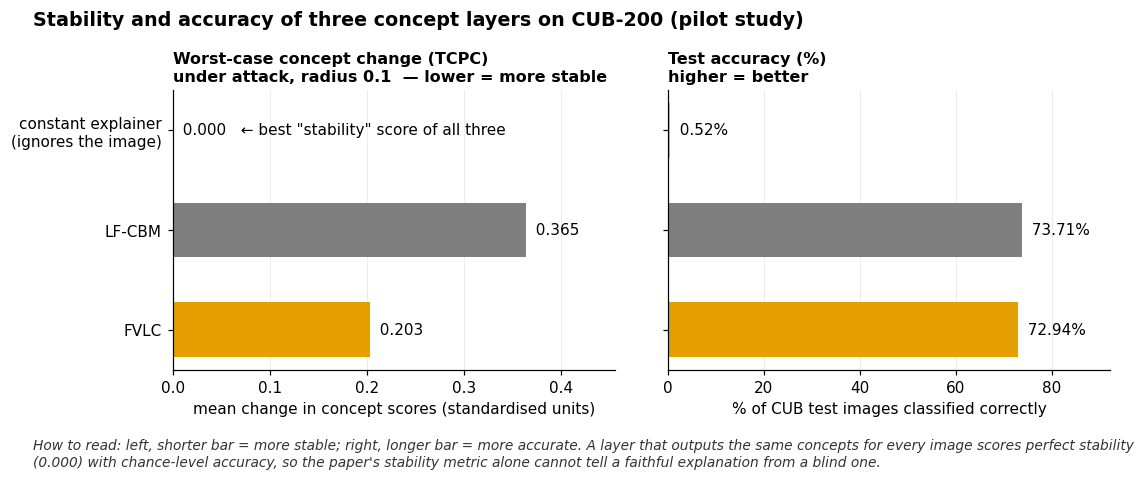

In [5]:
# ===================== Fig. A1 — The research gap: stability alone cannot detect a useless explainer =========
pm = PILOT['models']
rows = [('constant explainer\n(ignores the image)', 'constant', '#BBBBBB', 'X'),
        ('LF-CBM', 'lfcbm', COL['LF-CBM'], MRK['LF-CBM']),
        ('FVLC', 'fvlc', COL['FVLC'], MRK['FVLC'])]
panels = [('Worst-case concept change (TCPC)\nunder attack, radius 0.1  — lower = more stable',
           lambda m: pm[m]['worst_case']['0.1']['tcpc'], '{:.3f}'),
          ('Test accuracy (%)\nhigher = better', lambda m: 100 * pm[m]['acc'], '{:.2f}%')]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True, gridspec_kw={'wspace': 0.12})
y = np.arange(len(rows))[::-1]
for ax, (ttl, f, fmt) in zip(axes, panels):
    vals = [f(k) for _, k, _, _ in rows]
    ax.barh(y, vals, color=[c for *_, c, _ in rows], height=0.55)
    for yy, v, (_, key, _, _) in zip(y, vals, rows):
        extra = '   ← best "stability" score of all three' if (key == 'constant' and fmt == '{:.3f}') else ''
        ax.text(v, yy, '  ' + fmt.format(v) + extra, va='center', fontsize=10)
    ax.set_title(ttl, fontsize=10.5, loc='left')
    ax.set_xlim(0, max(vals) * 1.25); ax.grid(axis='y', alpha=0)
axes[0].set_xlabel('mean change in concept scores (standardised units)')
axes[1].set_xlabel('% of CUB test images classified correctly')
axes[0].set_yticks(y); axes[0].set_yticklabels([r[0] for r in rows])
fig.suptitle('Stability and accuracy of three concept layers on CUB-200 (pilot study)', x=0.01, ha='left',
             fontsize=12.5, fontweight='bold', y=1.1)
caption(fig, 'left, shorter bar = more stable; right, longer bar = more accurate. A layer that outputs the same '
             'concepts for every image scores perfect stability\n(0.000) with chance-level accuracy, so the '
             "paper's stability metric alone cannot tell a faithful explanation from a blind one.", y=-0.08)
save(fig, 'A1_gap_constant_explainer.png'); plt.show()


## 2. Proposed improvement: one extra loss term, L5 (concept infidelity)
EC-FVLC keeps FVLC's four losses unchanged and adds

$$L_5=\frac1k\sum_j\big(\Delta\tilde g_j-a_j\,\Delta s_j\big)^2,\qquad \Delta\tilde g_j=\tilde g_j(T(x))-\tilde g_j(x),\quad \Delta s_j=\frac{s_j(T(x))-s_j(x)}{\sigma_j}$$

* $T$ is a label-free image edit: **occlude**, **crop** or **CutMix**, which change the evidence, or a **nuisance** edit (noise, JPEG, brightness), which keeps it.
* $\Delta s_j$ is how much CLIP's image–text similarity for concept $j$ changes under the edit; $a_j$ is a fixed per-concept scale (the correlation of concept $j$ with CLIP on the training set).
* If the evidence does not change ($\Delta s\approx0$), L5 reduces to a **stability** term. If it does change, L5 asks the concept score to **move with it**.
* Setting $\lambda_5=0$ recovers FVLC exactly. As in FVLC, only the concept layer $W_c$ is trained, and no human concept labels are used.

L5 is the *explanation infidelity* objective of Yeh et al. (*On the (In)fidelity and Sensitivity of Explanations*, NeurIPS 2019), applied to the concept layer, with CLIP supplying the expected change.

## 3. Main result: EC-FVLC's concepts follow the visual evidence 39–71% more closely
The evidence correlation is measured with a **different CLIP (ViT-L/14) that was never used in training**, so EC-FVLC cannot score well just by copying its training signal.
The ablation (◇) is trained on exactly the same edited images but without L5. The gap between ◇ and ● is therefore the effect of the new loss itself, not of seeing more data.

In [ ]:
# ===================== Fig. A2 — Main result: concept scores follow the visual evidence (held-out CLIP) =======
models = [('lfcbm', 'LF-CBM (starting point of the paper)', COL['LF-CBM'], MRK['LF-CBM'], True),
          ('fvlc', 'FVLC (before)', COL['FVLC'], MRK['FVLC'], True),
          ('fvlc_views', 'FVLC trained on the same edits, no L5 (ablation)', COL['ablation'], MRK['ablation'], False),
          ('SEL', 'EC-FVLC (after, ours)', COL['EC-FVLC'], MRK['EC-FVLC'], True)]
off = np.linspace(0.3, -0.3, len(models))

fig, ax = plt.subplots(figsize=(10, 5.2))
yc = np.arange(len(DATASETS))[::-1] * 1.25

for (key, lab, col, mk, filled), dy in zip(models, off):
    xs = [get(ds, SEL[ds] if key == 'SEL' else key, 'ev_oracle') for ds in DATASETS]
    ys = yc + dy
    # horizontal lines from left axis to score
    for x, yv in zip(xs, ys):
        ax.plot([0.15, x], [yv, yv],
                color=col, lw=1.8, solid_capstyle='round', zorder=3)
    # endpoint marker
    ax.scatter(xs, ys, s=55, marker=mk, color=col if filled else 'white',
               edgecolor=col, linewidth=1.6, zorder=4, label=lab)
    for x, yv in zip(xs, ys):
        ax.text(x + 0.003, yv, f'{x:.3f}', va='center', fontsize=8.5, color=col)

for ds, yv in zip(DATASETS, yc):
    a, b = get(ds, 'fvlc', 'ev_oracle'), get(ds, SEL[ds], 'ev_oracle')
    ax.text(1.01, yv, f'{(b - a) / a * 100:+.0f}%', transform=ax.get_yaxis_transform(), va='center',
            fontsize=11, fontweight='bold', color=COL['EC-FVLC'])
    ax.axhline(yv - 0.62, color='#dddddd', lw=0.8)
ax.text(1.01, yc[0] + 0.58, 'change\nFVLC \u2192 EC-FVLC', transform=ax.get_yaxis_transform(),
        va='top', fontsize=8.5, fontweight='bold')
ax.set_yticks(yc); ax.set_yticklabels([DSN[d] for d in DATASETS], fontsize=10.5); ax.grid(axis='y', alpha=0)
ax.set_ylim(yc[-1] - 0.62, yc[0] + 0.62)
ax.set_xlim(0.15, 0.36)
ax.set_xlabel('evidence correlation  (Pearson r between concept-score change and CLIP evidence change; '
              '0 = unrelated, 1 = identical)')
ax.set_title('Evidence correlation on held-out test edits, measured with a CLIP model never used in training '
             '(ViT-L/14)', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9)
caption(fig, 'further right = concept scores rise and fall with what is actually visible after an image is occluded, '
             'cropped or mixed. The hollow diamond\nreceives the same edited images but no L5, so the gap between it '
             'and the blue circle is the effect of the new loss alone. Single run, seed 42.', y=-0.12)
save(fig, 'A2_main_result_evidence_corr.png'); plt.show()


## 4. Before vs after on every metric: gains in evidence-following and noise stability, at a cost in worst-case attack stability
The chart shows every metric we measured, including the ones that got worse. Accuracy is unchanged (within 0.2%).
On all three datasets, EC-FVLC's concepts follow the evidence more closely and move less under nuisance edits and input noise.
The costs: the top-10 concept set is kept less often under an adversarial attack (7–12% worse on all datasets), worst-case concept change is 34% worse on CUB,
and part locality on CUB drops, because L5 also lets concepts respond to evidence outside their own body part.

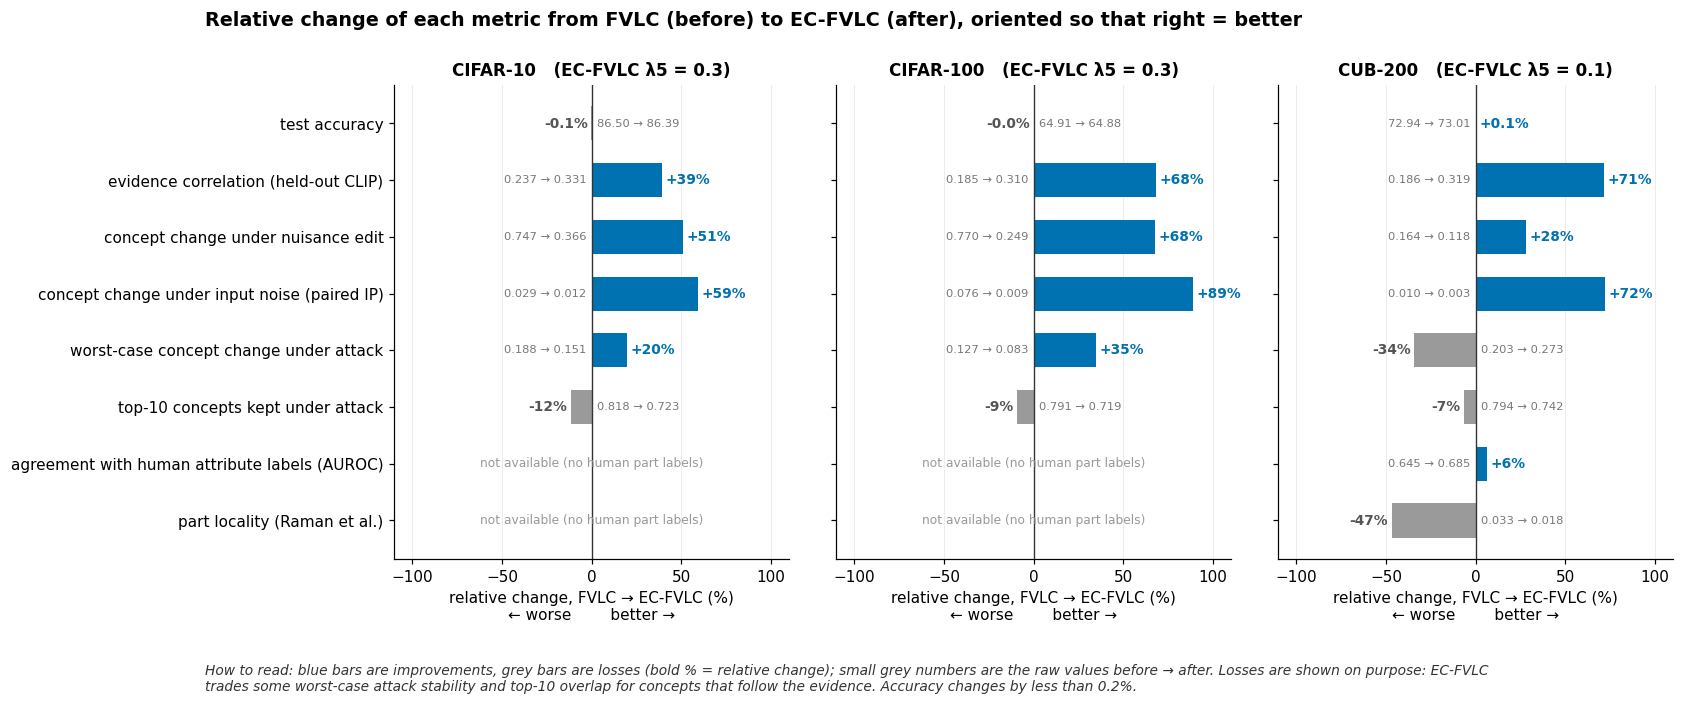

In [7]:
# ===================== Fig. A3 — Before vs after on every metric (gains AND losses) ==========================
METRICS = [  # (key, label, +1 if higher is better / -1 if lower is better)
    ('acc', 'test accuracy', +1),
    ('ev_oracle', 'evidence correlation (held-out CLIP)', +1),
    ('nuisance', 'concept change under nuisance edit', -1),
    ('ip_tcpc', 'concept change under input noise (paired IP)', -1),
    ('worst_tcpc', 'worst-case concept change under attack', -1),
    ('topk_overlap', 'top-10 concepts kept under attack', +1),
    ('auroc', 'agreement with human attribute labels (AUROC)', +1),
    ('locality', 'part locality (Raman et al.)', +1),
]
GAIN, LOSS = COL['EC-FVLC'], '#9A9A9A'

fig, axes = plt.subplots(1, 3, figsize=(15, 5.6), sharey=True, gridspec_kw={'wspace': 0.12})
y = np.arange(len(METRICS))[::-1]
for ax, ds in zip(axes, DATASETS):
    lim = 110
    for yy, (k, lab, d) in zip(y, METRICS):
        try:
            a, b = get(ds, 'fvlc', k), get(ds, SEL[ds], k)
        except KeyError:
            ax.text(0, yy, 'not available (no human part labels)', ha='center', va='center', fontsize=8, color='#999999')
            continue
        rel = d * (b - a) / abs(a) * 100
        ax.barh(yy, rel, color=GAIN if rel >= 0 else LOSS, height=0.6)
        fmt = '{:.2f}' if k == 'acc' else '{:.3f}'
        pos = rel >= 0
        ax.text(rel + (2 if pos else -2), yy, f'{rel:+.0f}%' if abs(rel) >= 0.5 else f'{rel:+.1f}%',
                ha='left' if pos else 'right', va='center', fontsize=9, fontweight='bold',
                color=GAIN if pos else '#555555')
        ax.text(-3 if pos else 3, yy, f'{fmt.format(a)} → {fmt.format(b)}', ha='right' if pos else 'left',
                va='center', fontsize=7.5, color='#777777')
    ax.axvline(0, color='#333333', lw=0.9)
    ax.set_xlim(-lim, lim); ax.set_xticks([-100, -50, 0, 50, 100]); ax.grid(axis='y', alpha=0)
    ax.set_title(f'{DSN[ds]}   (EC-FVLC λ5 = {SEL[ds].split("_l")[1]})', fontsize=11, loc='center')
    ax.set_xlabel('relative change, FVLC → EC-FVLC (%)\n← worse        better →')
axes[0].set_yticks(y); axes[0].set_yticklabels([m[1] for m in METRICS])
fig.suptitle('Relative change of each metric from FVLC (before) to EC-FVLC (after), oriented so that right = better',
             x=0.01, ha='left', fontsize=12.5, fontweight='bold', y=1.0)
caption(fig, 'blue bars are improvements, grey bars are losses (bold % = relative change); small grey numbers are the raw '
             'values before → after. Losses are shown on purpose: EC-FVLC\ntrades some worst-case attack stability and top-10 '
             'overlap for concepts that follow the evidence. Accuracy changes by less than 0.2%.', y=-0.06)
save(fig, 'A3_before_after_scorecard.png'); plt.show()


## 5. Choosing λ5: evidence correlation rises steadily with λ5 while accuracy holds until λ5 = 0.3 on CUB
Selection rule, fixed before looking at the results: take the highest held-out evidence correlation among the λ5 values whose accuracy stays within 1 point of FVLC.
On CUB, λ5 = 0.3 drops 1.3 points, so 0.1 is chosen. On the CIFAR datasets, 0.3 stays inside the band.

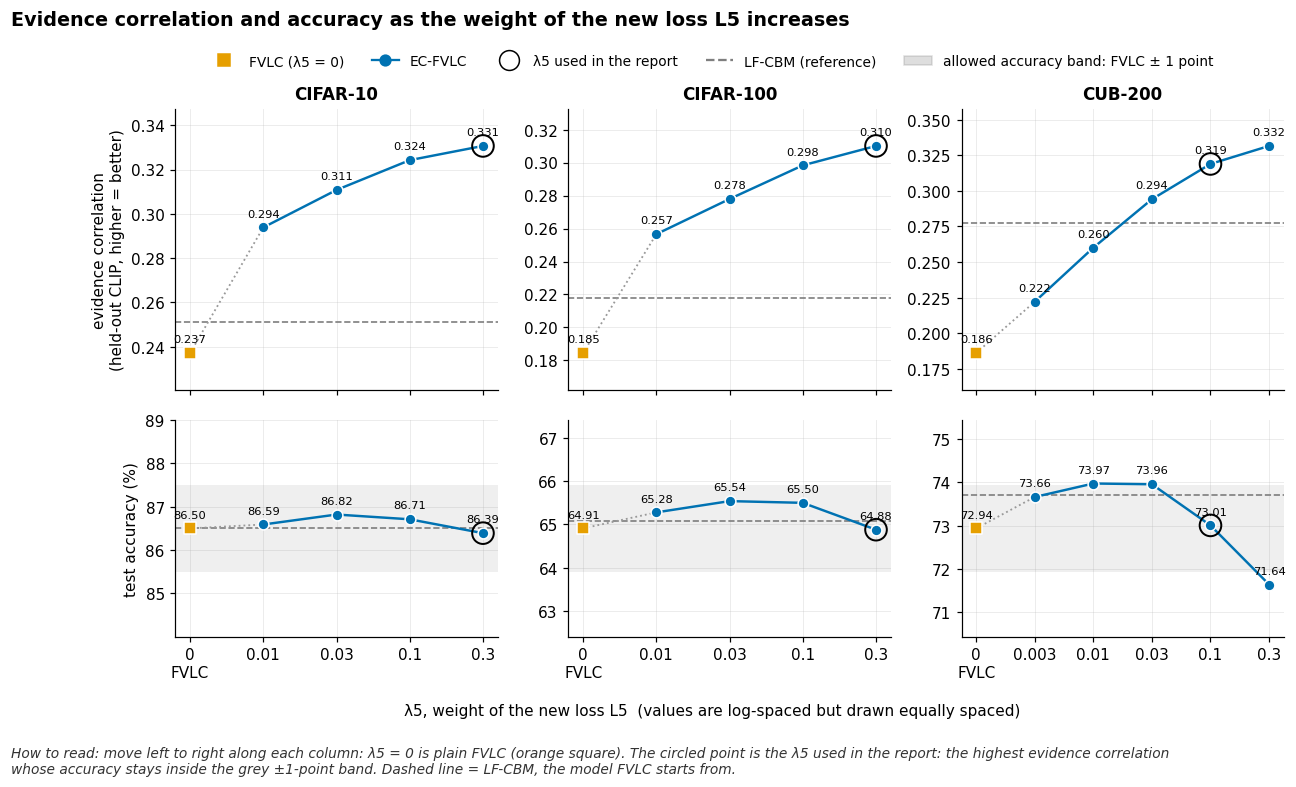

In [8]:
# ===================== Fig. A4 — Effect of the L5 weight λ5: evidence goes up, accuracy holds ===============
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex='col', gridspec_kw={'hspace': 0.12, 'wspace': 0.22, 'top': 0.86,
                                                                         'height_ratios': [1.3, 1]})
for c, ds in enumerate(DATASETS):
    lams = [0.0] + P2[ds]['lambda5']
    keys = ['fvlc'] + [f'ecfvlc_l{l:g}' for l in P2[ds]['lambda5']]
    x = np.arange(len(lams)); sel = keys.index(SEL[ds])
    for r, (metric, ylab) in enumerate([('ev_oracle', 'evidence correlation\n(held-out CLIP, higher = better)'),
                                        ('acc', 'test accuracy (%)')]):
        ax = axes[r, c]
        v = np.array([get(ds, k, metric) for k in keys])
        ref = get(ds, 'lfcbm', metric)
        if metric == 'acc':                                            # selection rule: within 1 point of FVLC
            ax.axhspan(v[0] - 1, v[0] + 1, color=COL['ref'], alpha=0.12, lw=0)
            ax.set_ylim(v[0] - 2.5, v[0] + 2.5)
        ax.axhline(ref, color=COL['LF-CBM'], ls='--', lw=1.1)
        ax.plot(x[1:], v[1:], '-', color=COL['EC-FVLC'], lw=1.6)
        ax.plot([x[0], x[1]], v[:2], ':', color='#999999', lw=1.2)
        ax.scatter(x[0], v[0], marker=MRK['FVLC'], s=60, color=COL['FVLC'], zorder=3, edgecolor='white')
        ax.scatter(x[1:], v[1:], marker=MRK['EC-FVLC'], s=50, color=COL['EC-FVLC'], zorder=3, edgecolor='white')
        ax.scatter(x[sel], v[sel], s=200, facecolor='none', edgecolor='black', lw=1.3, zorder=4)
        for xi, vi in zip(x, v):
            ax.annotate(f'{vi:.2f}' if metric == 'acc' else f'{vi:.3f}', (xi, vi), xytext=(0, 7),
                        textcoords='offset points', ha='center', fontsize=7.5)
        if c == 0: ax.set_ylabel(ylab)
        if r == 0: ax.set_title(DSN[ds], fontsize=11, loc='center')
        ax.margins(y=0.18)
    axes[1, c].set_xticks(x); axes[1, c].set_xticklabels(['0\nFVLC'] + [f'{l:g}' for l in lams[1:]])
fig.supxlabel('λ5, weight of the new loss L5  (values are log-spaced but drawn equally spaced)', fontsize=10, y=-0.005)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Line2D([], [], marker=MRK['FVLC'], color=COL['FVLC'], ls='', ms=8, label='FVLC (λ5 = 0)'),
                    Line2D([], [], marker=MRK['EC-FVLC'], color=COL['EC-FVLC'], ms=7, label='EC-FVLC'),
                    Line2D([], [], marker='o', mfc='none', mec='black', ls='', ms=13, label='λ5 used in the report'),
                    Line2D([], [], color=COL['LF-CBM'], ls='--', label='LF-CBM (reference)'),
                    Patch(color=COL['ref'], alpha=0.25, label='allowed accuracy band: FVLC ± 1 point')],
           loc='upper center', bbox_to_anchor=(0.5, 0.955), ncol=5, fontsize=9)
fig.suptitle('Evidence correlation and accuracy as the weight of the new loss L5 increases', x=0.01, ha='left',
             fontsize=12.5, fontweight='bold', y=1.0)
caption(fig, 'move left to right along each column: λ5 = 0 is plain FVLC (orange square). The circled point is the '
             'λ5 used in the report: the highest evidence correlation\nwhose accuracy stays inside the grey ±1-point '
             'band. Dashed line = LF-CBM, the model FVLC starts from.', y=-0.045)
save(fig, 'A4_lambda5_sweep.png'); plt.show()


## 6. Independent check with human labels: FVLC's loss in agreement with biologists is recovered
CUB-200 has attribute labels from biologists (for example *yellow belly* or *black wings*). This check uses no CLIP at all.
FVLC's stability training lowered agreement with the human labels (0.690 → 0.645); EC-FVLC brings it back to 0.685.
To be honest about this result: the ablation without L5 reaches the same value, so on this metric the gain comes from training on the edited images rather than from L5 specifically.

In [ ]:
# ===================== Fig. A5 — Check against human labels (CUB), independent of CLIP =========================
ds = 'cub'
models = [('lfcbm', 'LF-CBM', COL['LF-CBM'], MRK['LF-CBM'], True),
          ('fvlc', 'FVLC (before)', COL['FVLC'], MRK['FVLC'], True),
          ('fvlc_views', 'FVLC + edits, no L5', COL['ablation'], MRK['ablation'], False),
          (SEL[ds], 'EC-FVLC (after)', COL['EC-FVLC'], MRK['EC-FVLC'], True)]
groups = [('auroc', 'all images'), ('auroc_ws', 'within the same species')]
off = np.linspace(0.27, -0.27, len(models))

fig, ax = plt.subplots(figsize=(10, 3.9))
yc = np.array([1.0, 0.0])

for (k, lab, col, mk, filled), dy in zip(models, off):
    xs = [get(ds, k, g) for g, _ in groups]
    ys = yc + dy
    # line connecting the two group points for each model
    ax.plot(xs, ys, color=col, lw=1.8, solid_capstyle='round', zorder=2)
    # endpoint marker
    ax.scatter(xs, ys, s=70, marker=mk, color=col if filled else 'white',
               edgecolor=col, lw=1.6, zorder=3, label=lab)
    for x, yv in zip(xs, ys):
        ax.text(x + 0.003, yv, f'{x:.3f}', va='center', fontsize=8.5, color=col)

ax.axvline(0.5, color=COL['ref'], ls='--', lw=1.1)
ax.text(0.502, 1.42, 'chance (0.5)', fontsize=8.5, color='#555555', va='top')
ax.axhline(0.5, color='#dddddd', lw=0.8)
ax.set_yticks(yc); ax.set_yticklabels([g[1] for g in groups]); ax.grid(axis='y', alpha=0)
ax.set_ylim(-0.45, 1.45); ax.set_xlim(0.49, 0.72)
ax.set_xlabel('AUROC of concept score vs. biologists\' attribute labels  (0.5 = chance, 1.0 = perfect)')
ax.set_title('Agreement of concept scores with human attribute annotations on CUB-200 (110 concepts)', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=4, fontsize=9)
caption(fig, 'further right = a concept\'s score is higher on birds that experts labelled as having that attribute. '
             'No CLIP is used here, so this is independent of training.\nFVLC fell below LF-CBM; EC-FVLC returns to about '
             'the LF-CBM level, but so does training on the edits without L5 (hollow diamond): this gain is not specific to L5.',
        y=-0.2)
save(fig, 'A5_cub_human_attributes.png'); plt.show()


# Part B — Inside the model: what happens to images and concepts under each edit (CIFAR-10, GPU)
The next three cells reproduce the reported CIFAR-10 models: the same config and seed as `run_phase2.py`, with λ5 = 0.3.
They then compute, for every test image and every edit, how much each concept score moved (`R[model]['dg']`) and how much CLIP says its evidence moved (`target`).
Runtime is roughly 30–40 minutes on a T4.

In [10]:
DATASET = 'cifar10'                       # 'cifar10' | 'cifar100' | 'cub'
LAMBDA5 = {'cifar10': 0.3, 'cifar100': 0.3, 'cub': 0.1}[DATASET]   # the values selected in results_phase2/SUMMARY.md
SWEEP   = [0.01, 0.03, 0.1, 0.3]          # for the last figure
OUT = '/kaggle/working/viz_results'
FIG = '/kaggle/working/figures'
os.makedirs(FIG, exist_ok=True)

if DATASET == 'cub':
    !bash scripts/download_cub.sh

In [11]:
import numpy as np, torch
import matplotlib.pyplot as plt
from fvlc.config import get_config
from fvlc.pipeline import Experiment
from fvlc.phase2 import EvidenceData, get_or_train
from fvlc.features import view_features, text_features
from fvlc.data import get_dataset
from fvlc.views import apply_view, VIEW_IDS, EVIDENCE_VIEWS, NUISANCE_VIEWS
from fvlc import metrics as M
from fvlc.utils import get_device, set_seed

# identical to run_phase2.py defaults -> same layers as the reported results
cfg = get_config(DATASET, protocol='paired', fvlc_init='gaussian', seed=42)
device = get_device(None)
set_seed(cfg['seed'])
exp = Experiment(cfg, device, OUT)
exp.build_vanilla()                                   # LF-CBM (concept layer + final layer)
evidence = EvidenceData(exp, cfg['views'])            # edited training images + CLIP evidence targets for L5

lfcbm = exp.vanilla
fvlc  = get_or_train(exp, 'fvlc', 'fvlc', 0.0, False, evidence)                                  # BEFORE
ec    = get_or_train(exp, f'ecfvlc_l{LAMBDA5:g}', 'ecfvlc', LAMBDA5, False, evidence)            # AFTER

te = exp.feats('test')['backbone']
for name, L in [('LF-CBM', lfcbm), ('FVLC', fvlc), (f'EC-FVLC (lambda5={LAMBDA5:g})', ec)]:
    print(f'{name:28s} test accuracy {100 * M.accuracy(exp.final(L(te)), exp.y_test):.2f}')

100%|██████████| 170M/170M [56:50<00:00, 50.0kB/s]   
100%|████████████████████████████████████████| 244M/244M [00:02<00:00, 126MiB/s]
100%|████████████████████████████████████████| 335M/335M [00:03<00:00, 107MiB/s]


[vanilla] 143 concepts -> 138 after CLIP cutoff
  projection: best step 200, val similarity 0.6065
[vanilla] 131 concepts after interpretability cutoff


  8%|▊         | 85/1000 [00:46<08:16,  1.84it/s]


(0) lambda 0.0007, loss 0.4244, acc 0.8697 [val acc 0.8651] [test acc -1.0000], sparsity 0.2679389312977099 [351/1310], time 46.6203134059906, lr 0.1000
[vanilla] test acc 0.8651  (351/1310 non-zero final weights)


[train] fvlc
    FVLC epoch   1/20  loss 1.471e-02  L1 3.665e-01  L2 9.605e-01  L3 4.177e-02  L4 1.024e-01  L5 0.000e+00
    FVLC epoch   5/20  loss 3.332e-03  L1 1.112e-02  L2 1.995e-01  L3 3.423e-02  L4 8.837e-02  L5 0.000e+00
    FVLC epoch  10/20  loss 2.487e-03  L1 5.078e-03  L2 1.185e-01  L3 3.394e-02  L4 9.126e-02  L5 0.000e+00
    FVLC epoch  15/20  loss 2.187e-03  L1 3.630e-03  L2 9.147e-02  L3 3.373e-02  L4 8.990e-02  L5 0.000e+00
    FVLC epoch  20/20  loss 2.114e-03  L1 3.219e-03  L2 8.363e-02  L3 3.360e-02  L4 9.092e-02  L5 0.000e+00
[train] ecfvlc_l0.3
    FVLC epoch   1/20  loss 1.629e-01  L1 4.194e-01  L2 7.747e-01  L3 6.506e-02  L4 1.065e-01  L5 4.975e-01
    FVLC epoch   5/20  loss 1.044e-01  L1 1.086e-01  L2 3.353e-01  L3 5.810e-02  L4 1.463e-01  L5 3.265e-01
    FVLC epoch  10/20  loss 1.027e-01  L1 1.033e-01  L2 3.226e-01  L3 5.742e-02  L4 1.507e-01  L5 3.213e-01
    FVLC epoch  15/20  loss 1.020e-01  L1 9.997e-02  L2 3.160e-01  L3 5.694e-02  L4 1.512e-01  L5 3.191

In [12]:
# ---- everything below is converted to NumPy so the plotting cells are simple -------------------------------
VIEWS = list(cfg['views'])
e_idx = [i for i, v in enumerate(VIEWS) if v in EVIDENCE_VIEWS]     # evidence-changing edits
n_idx = [i for i, v in enumerate(VIEWS) if v in NUISANCE_VIEWS]     # evidence-preserving edits

vf = view_features(cfg, 'test', VIEWS, device)                      # cached; same edits as in run_phase2.py
clip0 = exp.feats('test')['clip'].float()
txt = text_features(cfg, exp.concepts, device).float()
t = txt / txt.norm(dim=1, keepdim=True)
s0 = (clip0 / clip0.norm(dim=1, keepdim=True)) @ t.T                                   # (N, k) clean evidence
cv = vf['clip'].float()
sv = (cv / cv.norm(dim=2, keepdim=True)) @ t.T                                         # (N, V, k) edited evidence
ds_t = sv - s0.unsqueeze(1)                                                            # CLIP evidence change
target_t = evidence.a.cpu() * ds_t / evidence.s_std.cpu()                              # in concept-activation units (what L5 asks for)
ds, target = ds_t.numpy(), target_t.numpy()

@torch.no_grad()
def analyse(layer):
    N, V, d = vf['backbone'].shape
    c0 = layer(te)
    cvv = layer(vf['backbone'].float().reshape(N * V, d)).reshape(N, V, -1)
    out = dict(dg=(cvv - c0.unsqueeze(1)).numpy(),
               pred0=exp.final(c0).argmax(1).numpy(),
               predv=exp.final(cvv).argmax(-1).numpy())
    out['nuis_tcpc'] = float(M.tcpc(c0, cvv[:, n_idx[0]])) if n_idx else float('nan')
    return out

R = {'LF-CBM': analyse(lfcbm), 'FVLC': analyse(fvlc), 'EC-FVLC': analyse(ec)}
test_ds = get_dataset(DATASET, 'test')                                                 # raw PIL images
y_test = exp.y_test.numpy()

def edited_image(i, view):
    """The very same edited image that was fed to the models (same RNG as fvlc/views.py ViewDataset)."""
    img = test_ds[i][0].convert('RGB')
    if view == 'clean':
        return img
    rng = np.random.default_rng([cfg['seed'], int(i), VIEW_IDS[view]])
    def other(r):
        j = int(r.integers(0, len(test_ds) - 1))
        return test_ds[j + (j >= i)][0]
    return apply_view(img, view, rng, other)

print('views:', VIEWS, '| N test:', len(y_test), '| concepts:', len(exp.concepts))

views: ['occlude', 'crop', 'cutmix', 'nuisance'] | N test: 10000 | concepts: 131


In [13]:
# ===================== Part B setup: per-image agreement scores (needs R, target, edited_image from above) =====
MODELS = ['FVLC', 'EC-FVLC']
REF_MODEL = 'LF-CBM' if 'LF-CBM' in R else None             # optional grey reference in Fig. 3

CONCEPTS = list(exp.concepts)
CLASSES = list(exp.classes)
E_VIEWS = [v for v in VIEWS if v != 'nuisance']             # edits that change the visual evidence
EDIT_TEXT = {                                                # plain-language description, matches fvlc/views.py
    'clean':    ('original', 'unedited\ntest image'),
    'occlude':  ('occlude', 'grey box over\n25-50% of image'),
    'crop':     ('crop', 'keep 20-50%,\nresize back'),
    'cutmix':   ('CutMix', 'paste 30-50% patch\nfrom another image'),
    'nuisance': ('nuisance', 'brightness, contrast,\nnoise, JPEG'),
}

def cname(j, n=30):
    s = CONCEPTS[j]
    return s if len(s) <= n else s[:n - 1] + '…'

def row_corr(x, y):
    """Pearson r across the last axis (concepts): one value per (image, edit)."""
    x = x - x.mean(-1, keepdims=True); y = y - y.mean(-1, keepdims=True)
    den = np.sqrt((x * x).sum(-1) * (y * y).sum(-1))
    return np.where(den > 1e-12, (x * y).sum(-1) / np.maximum(den, 1e-12), np.nan)

def mean_ci(v):
    """Mean and 95% CI (normal approximation; images are independent)."""
    v = v[np.isfinite(v)]
    m, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
    return m, m - 1.96 * se, m + 1.96 * se

# Per-image agreement: correlation, across all concepts, between how much each concept moved after the edit (dg)
# and how much CLIP says its evidence moved (target). 1 = concepts move exactly as the evidence does, 0 = unrelated.
AGREE = {m: row_corr(R[m]['dg'], target) for m in R}        # dict of (N, V) arrays
N, V, K = target.shape
print(f'{N} test images, {V} edits {VIEWS}, {K} concepts')
for m in AGREE:
    print(f'  {m:8s} mean per-image agreement on evidence edits: '
          f'{np.nanmean(AGREE[m][:, [VIEWS.index(v) for v in E_VIEWS]]):.3f}')

# -- Cache to disk so Part B plot cells can reload without re-running GPU cells --
import os as _os
_cache = dict(
    AGREE_FVLC=AGREE['FVLC'], AGREE_ECFVLC=AGREE['EC-FVLC'], AGREE_LFCBM=AGREE.get('LF-CBM', np.array([])),
    R_FVLC_dg=R['FVLC']['dg'], R_ECFVLC_dg=R['EC-FVLC']['dg'],
    R_FVLC_pred0=R['FVLC']['pred0'], R_ECFVLC_pred0=R['EC-FVLC']['pred0'],
    target=target, y_test=y_test,
    VIEWS_arr=np.array(VIEWS), CONCEPTS_arr=np.array(CONCEPTS), CLASSES_arr=np.array(CLASSES),
)
_cache_path = _os.path.join(OUT, 'partB_cache.npz')
np.savez(_cache_path, **_cache)
print(f'Saved Part B cache -> {_cache_path}')


10000 test images, 4 edits ['occlude', 'crop', 'cutmix', 'nuisance'], 131 concepts
  LF-CBM   mean per-image agreement on evidence edits: 0.502
  FVLC     mean per-image agreement on evidence edits: 0.482
  EC-FVLC  mean per-image agreement on evidence edits: 0.684


## 7a. The four edits used by L5
Occlude, crop and CutMix remove or replace what is visible, so the concept scores *should* change. The nuisance edit only adds noise, so they *should not*.

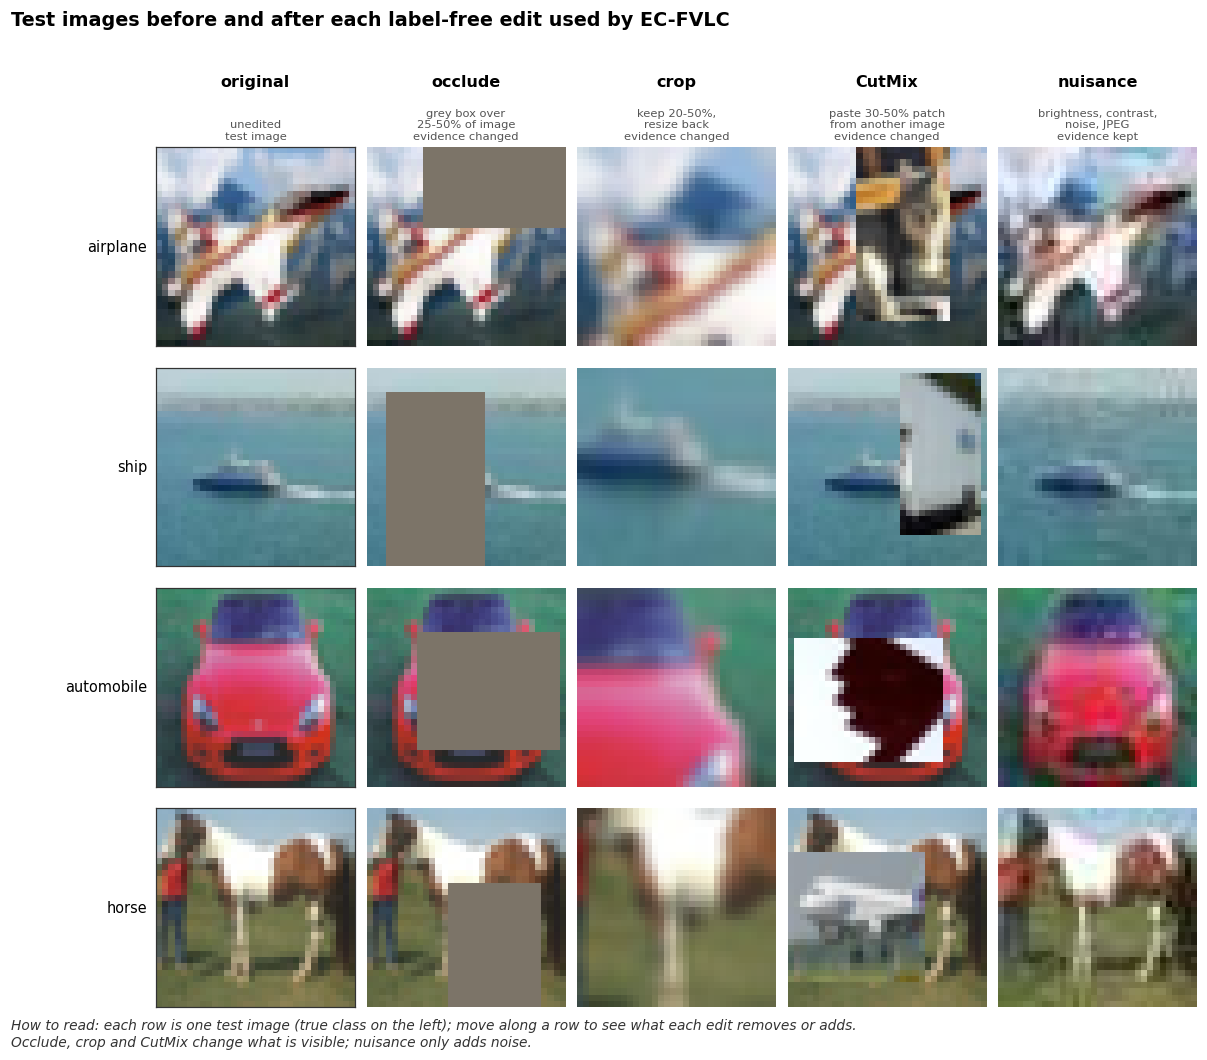

In [14]:
# ===================== Figure 1: what each edit does to an image =========================================
# Rows = randomly drawn test images (fixed seed, no cherry-picking). Columns = original + each edit.
N_ROWS = 4
rows = np.random.default_rng(0).choice(N, N_ROWS, replace=False)
cols = ['clean'] + list(VIEWS)

fig, axes = plt.subplots(N_ROWS, len(cols), figsize=(2.0 * len(cols) + 1.0, 2.0 * N_ROWS + 1.5), squeeze=False)
fig.subplots_adjust(left=0.13, right=0.99, top=1 - 1.25 / (2.0 * N_ROWS + 1.5), bottom=0.35 / (2.0 * N_ROWS + 1.5),
                    wspace=0.06, hspace=0.06)
for r, i in enumerate(rows):
    for c, v in enumerate(cols):
        ax = axes[r, c]
        ax.imshow(edited_image(i, v), interpolation='nearest')
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(c == 0); s.set_color('#333333')        # thin frame marks the original
        if r == 0:
            name, desc = EDIT_TEXT.get(v, (v, ''))
            kind = '' if v == 'clean' else ('\nevidence kept' if v == 'nuisance' else '\nevidence changed')
            ax.set_title(f'{name}', fontsize=10.5, loc='center', pad=40)
            ax.text(0.5, 1.03, desc + kind, transform=ax.transAxes, ha='center', va='bottom', fontsize=7.5, color='#555555')
    axes[r, 0].set_ylabel(CLASSES[int(y_test[i])].replace('_', ' '), fontsize=9.5, rotation=0, ha='right', va='center', labelpad=6)

fig.suptitle('Test images before and after each label-free edit used by EC-FVLC', x=0.01, ha='left',
             fontsize=12.5, fontweight='bold', y=0.995)
caption(fig, 'each row is one test image (true class on the left); move along a row to see what each edit '
             'removes or adds.\nOcclude, crop and CutMix change what is visible; nuisance only adds noise.', y=0.03)
save(fig, 'B1_edit_gallery.png'); plt.show()


## 7b. One image, one edit: EC-FVLC moves its concepts in the direction CLIP's evidence moves
The image shown is the typical case (median gain), not the best one. Set `IDX` or `VIEW` to look at others.

In [ ]:
# ===================== Figure 2: one image, one edit — which concepts went up or down? ====================
# -- If GPU cells (19-21) were not run in this session, reload from cache saved by cell 21 --
if 'VIEWS' not in dir() or 'AGREE' not in dir():
    import os as _os, numpy as _np
    _out = OUT if 'OUT' in dir() else '/kaggle/working/viz_results'
    _cp  = _os.path.join(_out, 'partB_cache.npz')
    _d   = _np.load(_cp, allow_pickle=False)
    VIEWS    = list(_d['VIEWS_arr'])
    CONCEPTS = list(_d['CONCEPTS_arr'])
    CLASSES  = list(_d['CLASSES_arr'])
    target   = _d['target']
    y_test   = _d['y_test']
    N, V, K  = target.shape
    AGREE = {'FVLC': _d['AGREE_FVLC'], 'EC-FVLC': _d['AGREE_ECFVLC']}
    if _d['AGREE_LFCBM'].ndim > 0 and _d['AGREE_LFCBM'].size > 0:
        AGREE['LF-CBM'] = _d['AGREE_LFCBM']
    R = {
        'FVLC':    {'dg': _d['R_FVLC_dg'],   'pred0': _d['R_FVLC_pred0']},
        'EC-FVLC': {'dg': _d['R_ECFVLC_dg'], 'pred0': _d['R_ECFVLC_pred0']},
    }
    def edited_image(i, view):
        import numpy as __np
        from PIL import Image as __Image
        placeholder = __np.full((32, 32, 3), 200, dtype=__np.uint8)
        return __Image.fromarray(placeholder)
    def cname(j, n=30):
        s = CONCEPTS[j]
        return s if len(s) <= n else s[:n-1] + '...'
    print('Loaded Part B cache from disk (no GPU needed for this cell).')

VIEW = 'occlude'      # any of VIEWS except 'nuisance'
IDX = None            # set a test-image index to show a specific image; None = the typical (median) image
TOP = 10              # number of concepts shown

vi = VIEWS.index(VIEW)
if IDX is None:
    adv = AGREE['EC-FVLC'][:, vi] - AGREE['FVLC'][:, vi]
    ok = np.where(np.isfinite(adv))[0]
    IDX = int(ok[np.argsort(adv[ok])[len(ok) // 2]]); how = 'median EC-FVLC gain over FVLC (typical case)'
else:
    how = 'chosen by hand'
i = IDX

tg = target[i, vi]
show = np.argsort(-np.abs(tg))[:TOP]
show = show[np.argsort(tg[show])]
y = np.arange(len(show))

fig = plt.figure(figsize=(11, 0.42 * TOP + 2.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 4.4], wspace=0.6, hspace=0.25)
for k, v in enumerate(['clean', VIEW]):
    a = fig.add_subplot(gs[k, 0]); a.imshow(edited_image(i, v), interpolation='nearest')
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a.set_title('original' if v == 'clean' else 'after "%s"' % VIEW, fontsize=10, loc='center')

ax = fig.add_subplot(gs[:, 1])

# CLIP evidence bars (grey background reference)
ax.barh(y, tg[show], height=0.62, color=COL['ref'], alpha=0.35, label='CLIP evidence change (reference)')
for j2, (yv2, val2) in enumerate(zip(y, tg[show])):
    ax.text(val2 + 0.02, yv2, '%.2f' % val2, va='center', ha='left', fontsize=7.5, color='#555555')

# FVLC and EC-FVLC: horizontal lines from 0 to score, with score at tip
for m, lw, zord in [('FVLC', 2.2, 3), ('EC-FVLC', 2.2, 4)]:
    xs = R[m]['dg'][i, vi, show]
    offset = 0.13 if m == 'FVLC' else -0.13
    for j2, (yv2, val2) in enumerate(zip(y, xs)):
        ax.plot([0, val2], [yv2 + offset, yv2 + offset],
                color=COL[m], lw=lw, solid_capstyle='round', zorder=zord,
                label=m if j2 == 0 else None)
        ax.text(val2 + 0.02, yv2 + offset, '%.2f' % val2,
                va='center', ha='left', fontsize=7.5, color=COL[m])

ax.axvline(0, color='#333333', lw=0.9)
ax.set_yticks(y); ax.set_yticklabels([cname(j2, 26) for j2 in show]); ax.grid(axis='y', alpha=0)
ax.set_xlabel('change in concept score after the edit  (training standard deviations; + = concept went up)')
r_fvlc   = AGREE['FVLC'][i, vi]
r_ecfvlc = AGREE['EC-FVLC'][i, vi]
cls_name = CLASSES[int(y_test[i])].replace('_', ' ')
ax.set_title('Change in the %d concepts with the largest CLIP evidence change, test image %d (%s, edit: %s)\n'
             'agreement over all %d concepts (Pearson r):  FVLC %.2f   |   EC-FVLC %.2f'
             % (TOP, i, cls_name, VIEW, K, r_fvlc, r_ecfvlc), fontsize=10.5)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=9)

caption(fig, 'a grey bar is how much CLIP says the evidence for that concept changed; '
             'a line ending at the same x means the model moved the concept by the same amount. '
             '\nImage picked by: %s.' % how, y=-0.04)
save(fig, 'B2_single_image_%s_%d.png' % (VIEW, i)); plt.show()


## 7c. The same comparison over all test images, for each edit type, with 95% confidence intervals
Here agreement is computed **per image**, across concepts. Section 3 computed it per concept, across images, so the numbers differ, but the two should rank the models the same way.
This chart uses the *training* CLIP, which is the same signal L5 was trained with; the held-out CLIP result is in section 3.

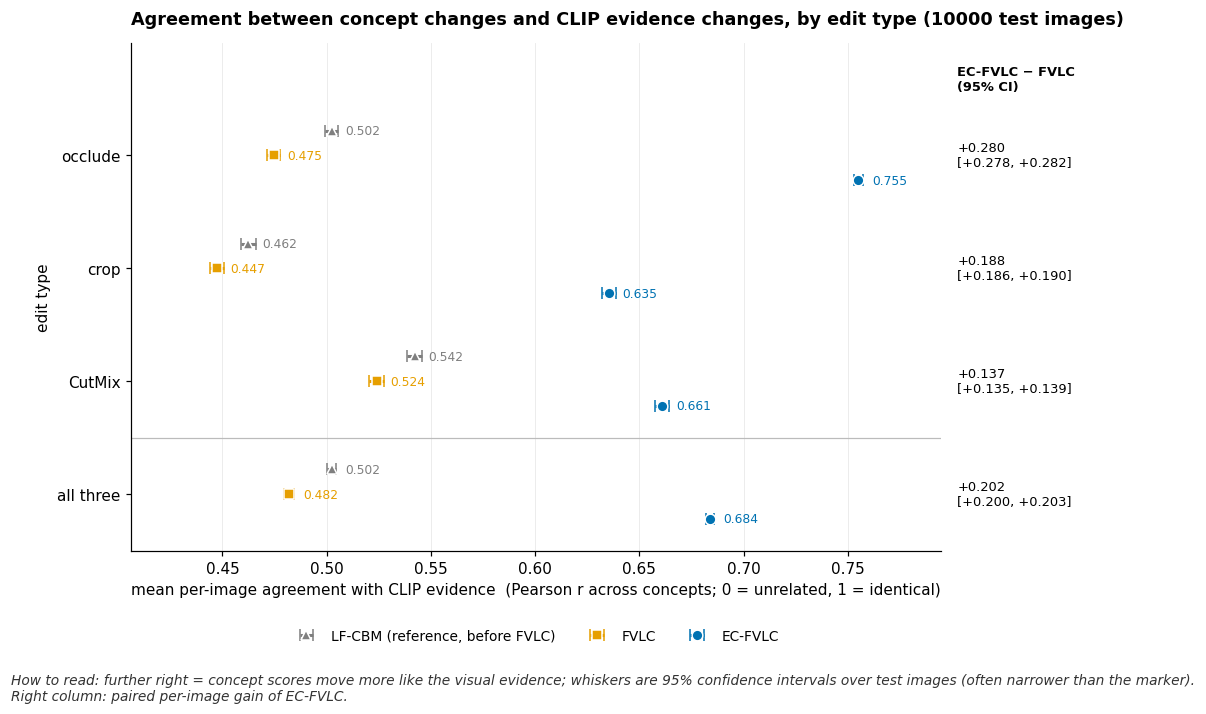

In [16]:
# ===================== Figure 3: how closely each model follows the evidence, per edit type ================
groups = [(v, [VIEWS.index(v)]) for v in E_VIEWS] + [('all three', [VIEWS.index(v) for v in E_VIEWS])]
order = ([REF_MODEL] if REF_MODEL else []) + MODELS
off = dict(zip(order, np.linspace(0.22, -0.22, len(order))))

fig, ax = plt.subplots(figsize=(9.5, 1.1 * len(groups) + 1.6))
yy = np.arange(len(groups))[::-1]
diff_txt = []
for m in order:
    stats = np.array([mean_ci(np.nanmean(AGREE[m][:, idx], axis=1)) for _, idx in groups])   # per-image value, then mean
    col = COL[m]
    ax.errorbar(stats[:, 0], yy + off[m], xerr=[stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]], fmt=MRK[m],
                color=col, ms=7, lw=2, capsize=4, markeredgecolor='white',
                label=f'{m} (reference, before FVLC)' if m == REF_MODEL else m)
    for x, yv in zip(stats[:, 0], yy + off[m]):
        ax.annotate(f'{x:.3f}', (x, yv), xytext=(9, 0), textcoords='offset points', va='center', fontsize=8, color=col)

# paired difference EC-FVLC - FVLC per image, shown as text on the right
for (g, idx), yv in zip(groups, yy):
    d = np.nanmean(AGREE['EC-FVLC'][:, idx], 1) - np.nanmean(AGREE['FVLC'][:, idx], 1)
    m_, lo, hi = mean_ci(d)
    ax.text(1.02, yv, f'{m_:+.3f}\n[{lo:+.3f}, {hi:+.3f}]', transform=ax.get_yaxis_transform(), va='center', fontsize=8.5)
ax.text(1.02, yy[0] + 0.55, 'EC-FVLC − FVLC\n(95% CI)', transform=ax.get_yaxis_transform(), va='bottom', fontsize=8.5, fontweight='bold')
if len(groups) > 1:
    ax.axhline(yy[-1] + 0.5, color='#bbbbbb', lw=0.8)

ax.set_yticks(yy); ax.set_yticklabels([EDIT_TEXT.get(g, (g,))[0] for g, _ in groups])
ax.set_ylabel('edit type'); ax.grid(axis='y', alpha=0)
ax.set_xlabel('mean per-image agreement with CLIP evidence  (Pearson r across concepts; 0 = unrelated, 1 = identical)')
ax.margins(x=0.12)
ax.set_ylim(yy[-1] - 0.5, yy[0] + 1.0)
ax.set_title(f'Agreement between concept changes and CLIP evidence changes, by edit type ({N} test images)', fontsize=11.5, pad=12)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=len(order), fontsize=9)

caption(fig, 'further right = concept scores move more like the visual evidence; whiskers are 95% confidence intervals '
             'over test images (often narrower than the marker).\nRight column: paired per-image gain of EC-FVLC.', y=-0.075)
save(fig, 'B3_agreement_by_edit.png'); plt.show()


## 7d. Nuisance edit: EC-FVLC's concepts move less when the evidence does not change

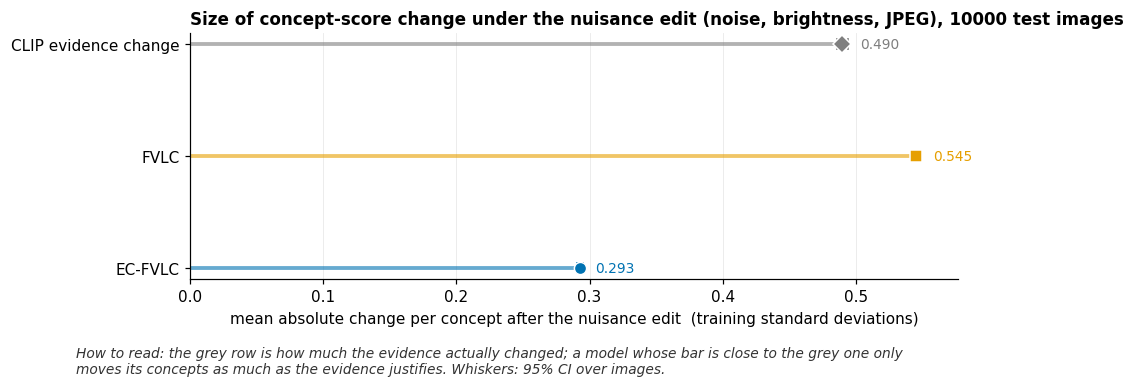

In [17]:
# ===================== Figure 3b: the nuisance edit — do concepts stay still when the evidence does? =========
# Agreement (r) is not meaningful here because CLIP's evidence barely changes, so we show the size of the change.
ni = VIEWS.index('nuisance')
rows3 = [('CLIP evidence change', np.abs(target[:, ni]).mean(1), COL['ref'], 'D')] + \
        [(m, np.abs(R[m]['dg'][:, ni]).mean(1), COL[m], MRK[m]) for m in MODELS]

fig, ax = plt.subplots(figsize=(9, 2.9))
for k, (lab, v, col, mk) in enumerate(rows3):
    m_, lo, hi = mean_ci(v)
    yv = len(rows3) - 1 - k
    ax.hlines(yv, 0, m_, color=col, lw=2.5, alpha=0.6)
    ax.errorbar(m_, yv, xerr=[[m_ - lo], [hi - m_]], fmt=mk, color=col, ms=8, capsize=4, markeredgecolor='white')
    ax.annotate(f'{m_:.3f}', (hi, yv), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9, color=col)
ax.set_yticks(range(len(rows3))); ax.set_yticklabels([r[0] for r in rows3][::-1]); ax.grid(axis='y', alpha=0)
ax.set_xlim(0, None); ax.margins(x=0.15)
ax.set_xlabel('mean absolute change per concept after the nuisance edit  (training standard deviations)')
ax.set_title(f'Size of concept-score change under the nuisance edit (noise, brightness, JPEG), {N} test images', fontsize=11)
caption(fig, 'the grey row is how much the evidence actually changed; a model whose bar is close to the grey one only\n'
             'moves its concepts as much as the evidence justifies. Whiskers: 95% CI over images.', y=-0.1)
save(fig, 'B4_nuisance_change.png'); plt.show()


## 7e. The improvement shifts the whole distribution, not just a few images

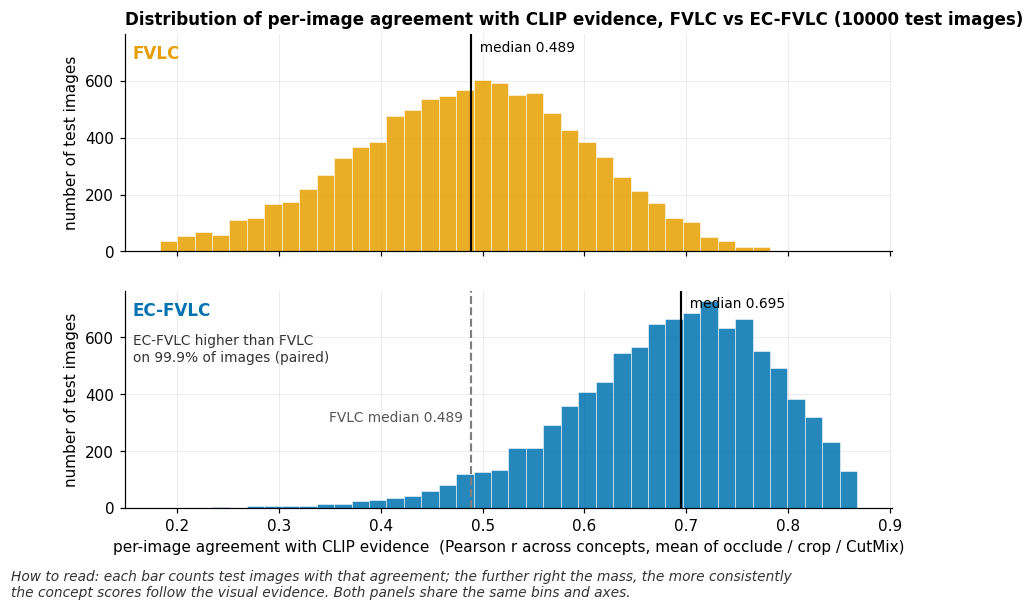

In [18]:
# ===================== Figure 4: distribution of per-image agreement, FVLC vs EC-FVLC ======================
e_ix = [VIEWS.index(v) for v in E_VIEWS]
per_img = {m: np.nanmean(AGREE[m][:, e_ix], axis=1) for m in MODELS}      # one value per test image
better = np.mean(per_img['EC-FVLC'] > per_img['FVLC']) * 100
lo_, hi_ = np.nanpercentile(np.concatenate(list(per_img.values())), [0.5, 99.5])
bins = np.linspace(lo_, hi_, 41)                                           # same bins for both panels

fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, sharey=True, gridspec_kw={'hspace': 0.18})
for ax, m in zip(axes, MODELS):
    v = per_img[m]
    ax.hist(v, bins=bins, color=COL[m], alpha=0.85, edgecolor='white', linewidth=0.4)
    med = np.nanmedian(v)
    ax.axvline(med, color='black', lw=1.4)
    ax.text(med, 0.97, f'  median {med:.3f}', transform=ax.get_xaxis_transform(), va='top', fontsize=9)
    if m == 'EC-FVLC':                                                     # FVLC's median for direct comparison
        mf = np.nanmedian(per_img['FVLC'])
        ax.axvline(mf, color=COL['ref'], lw=1.4, ls='--')
        ax.text(mf, 0.45, f'FVLC median {mf:.3f}  ', transform=ax.get_xaxis_transform(), va='top', ha='right',
                fontsize=9, color='#555555')
    ax.text(0.01, 0.95, m, transform=ax.transAxes, fontsize=11, fontweight='bold', color=COL[m], va='top')
    ax.set_ylabel('number of test images')
axes[1].set_xlabel('per-image agreement with CLIP evidence  (Pearson r across concepts, mean of occlude / crop / CutMix)')
axes[0].set_title(f'Distribution of per-image agreement with CLIP evidence, FVLC vs EC-FVLC ({N} test images)', fontsize=11)
axes[1].text(0.01, 0.80, f'EC-FVLC higher than FVLC\non {better:.1f}% of images (paired)', transform=axes[1].transAxes,
             ha='left', va='top', fontsize=9, color='#333333')
caption(fig, 'each bar counts test images with that agreement; the further right the mass, the more consistently\n'
             'the concept scores follow the visual evidence. Both panels share the same bins and axes.', y=0.01)
save(fig, 'B5_agreement_histogram.png'); plt.show()


# Conclusions and limitations
**Finding.** FVLC improves stability, but its concept scores follow the visual evidence *less* than the LF-CBM it starts from (A2, A5), and a blind constant explainer beats it on stability (A1).
**Contribution.** One label-free loss term, L5, makes the concept layer respond to real evidence changes on all three datasets (+39% to +71% on a held-out CLIP), with no loss of accuracy. It also improves stability under nuisance edits and input noise (A3).

**Limitations**
* Worst-case adversarial stability and top-10 overlap get worse (A3). L5 and FVLC's L4 pull in opposite directions, and λ5 controls the trade-off (A4).
* Part locality on CUB drops (A3): concepts respond to evidence anywhere in the image, not only on their own body part.
* "Evidence" is defined by CLIP. We use a held-out CLIP (A2) and human labels (A5) to check that EC-FVLC is not just copying its training signal, but CLIP's own biases can still carry over.
* The human-label gain (A5) is matched by the no-L5 ablation.
* All results are from a single seed (42); confidence intervals in Part B cover test images only, not training runs.

In [19]:
from IPython.display import FileLink
os.chdir('/kaggle/working')
!zip -qr figures.zip figures
FileLink('figures.zip')

/kaggle/working/figures.zip